# ABC/XYZ Class Analysis Prediction
#### Using Random Forest and XGBoost

#### RANDOM FOREST

Execution Time (Training + Prediction): 0.4365 seconds
Accuracy: 0.9478
Macro F1 Score: 0.6255
Macro Recall: 0.5930

Confusion Matrix:
[[  0   2   0   0   0   0   0   0   0]
 [  0 218   0   0   0   0   0   0   0]
 [  0   4   1   0   0   0   0   0   0]
 [  0   0   0   8   2   0   0   0   0]
 [  0   0   0   0 156   0   0   4   0]
 [  0   0   0   0   5   2   0   0   0]
 [  0   0   0   2   0   0 148   0   0]
 [  0   0   0   0   1   0   0 173   0]
 [  0   0   0   0   0   0   0  19   2]]


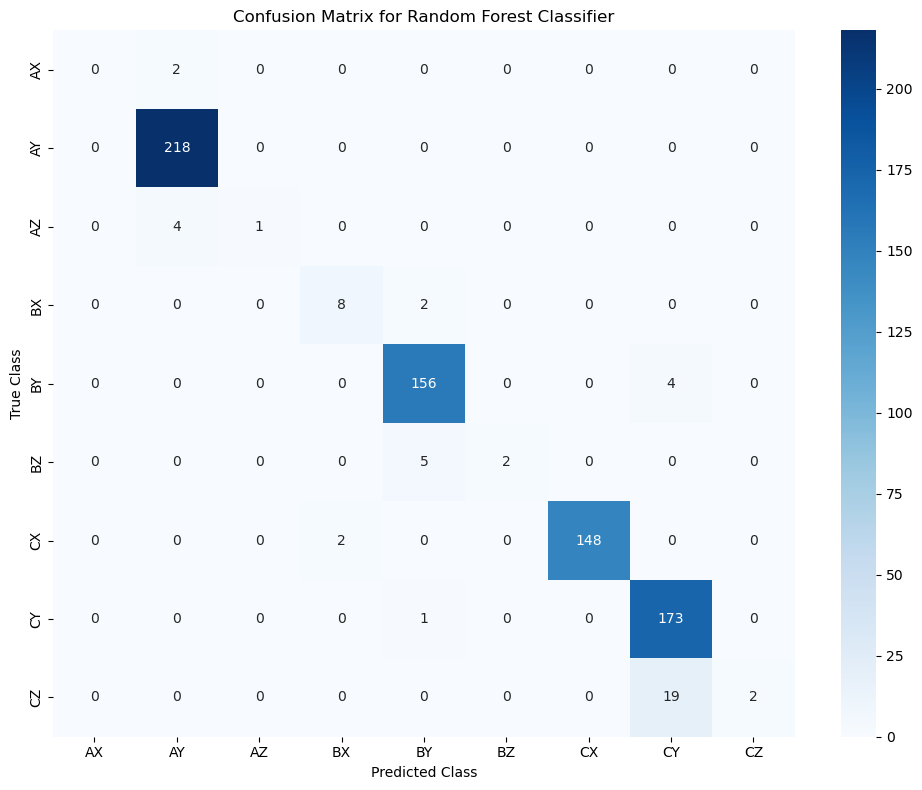

In [1]:
#random forest

import pandas as pd
import time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('Project IMS.csv')

# --- 1. Data Preparation ---
# Define features (X) and target (y)
# Features: columns from index 0 to 21 (Category up to Annual_Consumption)
# Target: 'Combined_Class'

X = df.loc[:,['Category', 'name', 'mrp', 'availableQuantity',
       'discountedSellingPrice', 'quantity','Annual_Consumption', 'Annual_Value','Mean_Demand', 'Std_Demand']]
y = df['Combined_Class']

# Handle categorical features in X using one-hot encoding
categorical_cols = X.select_dtypes(include=['object', 'bool']).columns
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# --- 2. Data Splitting (80% Train, 20% Test) ---
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# --- 3. Model Training and Prediction ---
start_time = time.time()

# Initialize and train the Random Forest classifier
rf_classifier = RandomForestClassifier(random_state=42)
rf_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_classifier.predict(X_test)

end_time = time.time()
execution_time = end_time - start_time

# --- 4. Metric Calculation ---
conf_matrix = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
# macro F1 and Recall are calculated across all classes, then averaged.
macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
macro_recall = recall_score(y_test, y_pred, average='macro', zero_division=0)

# --- 5. Visualization of Confusion Matrix ---
plt.figure(figsize=(10, 8))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d', # 'd' formats the annotation as an integer
    cmap='Blues',
    xticklabels=rf_classifier.classes_,
    yticklabels=rf_classifier.classes_
)
plt.title('Confusion Matrix for Random Forest Classifier')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.savefig('confusion_matrix_rf.png')

# Print calculated metrics
print(f"Execution Time (Training + Prediction): {execution_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix)

### XGBOOST

In [ ]:
# xgboost 

import pandas as pd
import time
from sklearn.model_selection import train_test_split
# Using GradientBoostingClassifier as XGBoost is unavailable
from sklearn.ensemble import GradientBoostingClassifier 
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasetx
df = pd.read_csv('Project IMS.csv')

# --- 1. Data Preparation ---
# Define features (X) and target (y)
# Features: columns from index 0 to 21 (Category up to Annual_Consumption)
X = df.loc[:,['Category', 'name', 'mrp', 'availableQuantity',
       'discountedSellingPrice', 'quantity','Annual_Consumption', 'Annual_Value','Mean_Demand', 'Std_Demand']]
y = df['Combined_Class']

# Handle categorical features in X using one-hot encoding
categorical_cols = X.select_dtypes(include=['object', 'bool']).columns
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Encode the target variable (y)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
class_labels = le.classes_ # Store the original class names

# --- 2. Data Splitting (80% Train, 20% Test) ---
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# --- 3. Model Training and Prediction ---
start_time = time.time()

# Initialize and train the Gradient Boosting classifier
gb_classifier = GradientBoostingClassifier(random_state=42)
gb_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = gb_classifier.predict(X_test)
end_time = time.time()
execution_time = end_time - start_time

# --- 4. Metric Calculation ---
conf_matrix = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
macro_recall = recall_score(y_test, y_pred, average='macro', zero_division=0)

# --- 5. Output Metrics and Confusion Matrix ---
print("\n--- Model Performance Metrics (Gradient Boosting Classifier) ---")
print(f"Execution Time (Training + Prediction): {execution_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")
print("\nConfusion Matrix (Label Encoded):")
print(conf_matrix)

# --- 6. Visualization of Confusion Matrix ---
plt.figure(figsize=(10, 8))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title('Confusion Matrix for Gradient Boosting Classifier')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.savefig('confusion_matrix_gb.png')
print("Confusion Matrix plot saved as 'confusion_matrix_gb.png'")
